# Baseline Model - TF-IDF + Logistic Regression

## 1. Introduction

In this notebook, we build a baseline machine learning model
for Toxic Comment Classification.

We use TF-IDF for text representation and Logistic Regression
as the classification algorithm.

Since each comment can belong to multiple toxicity categories,
we use a Multi-Label Classification approach.

### Objectives

- Load the saved processed data.
- Train a Logistic Regression baseline model.
- Evaluate model performance on the validation dataset.
- Calculate Precision, Recall, and F1-score.
- Generate a classification report for all six labels.

## 2. Importing Libraries and Loading Processed Data

In this section, we import the libraries required to train and evaluate the baseline model.

We also load the previously saved TF-IDF feature matrices and target labels.

The same processed features and labels will be used throughout the model development stage.

In [17]:
# Data Manipulation
import pandas as pd
import numpy as np

# Machine Learning
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

# Model Evaluation
from sklearn.metrics import (
    classification_report,
    f1_score,
    precision_score,
    recall_score
)

# Sparse Matrix Loading
from scipy.sparse import load_npz

# Load TF-IDF Matrices
X_train = load_npz("../data/processed/X_train_tfidf.npz")
X_val = load_npz("../data/processed/X_val_tfidf.npz")

# Load Target Labels
y_train = pd.read_csv("../data/processed/y_train.csv")
y_val = pd.read_csv("../data/processed/y_val.csv")

print("Libraries imported and processed data loaded successfully!")

Libraries imported and processed data loaded successfully!


In [18]:
print("Training Features:", X_train.shape)
print("Training Labels:", y_train.shape)

print("\nValidation Features:", X_val.shape)
print("Validation Labels:", y_val.shape)

Training Features: (127651, 50000)
Training Labels: (127651, 6)

Validation Features: (31913, 50000)
Validation Labels: (31913, 6)


## 3. Initializing the Baseline Model

In this section, we initialize the Logistic Regression classifier.

We use the OneVsRestClassifier strategy to handle the multi-label classification problem.

This approach trains one independent binary classifier for each toxicity category.

Since our dataset contains six target labels, six Logistic Regression classifiers will be trained.

In [19]:
# Initialize Logistic Regression

base_model = LogisticRegression(
    C=1.0,
    max_iter=1000,
    solver="liblinear"
)

# Wrap the Model for Multi-Label Classification

baseline_model = OneVsRestClassifier(base_model)

print("Baseline model initialized successfully!")
print("Number of classifiers:", len(y_train.columns))

Baseline model initialized successfully!
Number of classifiers: 6


## 4. Training the Baseline Model

In this section, we train the Logistic Regression baseline model using the TF-IDF training features and their corresponding target labels.

The OneVsRestClassifier trains six independent binary classifiers, one for each toxicity category.

The model learns patterns from the training data that will be used to predict toxicity labels for unseen comments.

In [20]:
import time

# Start Training Timer
start_time = time.time()

# Train the Baseline Model
baseline_model.fit(X_train, y_train)

# Calculate Training Time
training_time = time.time() - start_time

print("Baseline Model Training Completed!")
print(f"Training Time: {training_time:.2f} seconds")

Baseline Model Training Completed!
Training Time: 6.14 seconds


## 5. Making Predictions on Validation Data

In this section, we use the trained baseline model to predict the six toxicity labels for the validation dataset.

The predictions will be compared with the actual validation labels to evaluate model performance.

In [21]:
# Start Prediction Timer
start_time = time.time()

# Generate Predictions
y_val_pred = baseline_model.predict(X_val)

# Calculate Prediction Time
prediction_time = time.time() - start_time

print("Validation Predictions Completed!")
print("Prediction Shape:", y_val_pred.shape)
print(f"Prediction Time: {prediction_time:.2f} seconds")

Validation Predictions Completed!
Prediction Shape: (31913, 6)
Prediction Time: 0.03 seconds


## 6. Model Evaluation

In this section, we evaluate the baseline model using the validation dataset.

We calculate Precision, Recall, and F1-score for each toxicity category to understand the model's classification performance.

In [22]:
# Generate Classification Report
# Define Target Label Names

target_columns = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]
report = classification_report(
    y_val,
    y_val_pred,
    target_names=target_columns,
    zero_division=0
)

print("Classification Report:")
print(report)

Classification Report:
               precision    recall  f1-score   support

        toxic       0.92      0.57      0.71      3023
 severe_toxic       0.57      0.24      0.33       309
      obscene       0.93      0.59      0.72      1672
       threat       0.92      0.11      0.19       101
       insult       0.86      0.50      0.63      1570
identity_hate       0.70      0.11      0.18       301

    micro avg       0.89      0.52      0.66      6976
    macro avg       0.81      0.35      0.46      6976
 weighted avg       0.88      0.52      0.65      6976
  samples avg       0.05      0.04      0.05      6976



## 7. Evaluation Metrics Summary

In this section, we extract the evaluation metrics for each toxicity category.

The results will be stored in a structured DataFrame to support comparison with other machine learning models.

In [23]:
# Calculate Evaluation Metrics for Each Label

precision = precision_score(
    y_val, y_val_pred, average=None, zero_division=0
)

recall = recall_score(
    y_val, y_val_pred, average=None, zero_division=0
)

f1 = f1_score(
    y_val, y_val_pred, average=None, zero_division=0
)

# Create Evaluation DataFrame

evaluation_results = pd.DataFrame({
    "Label": target_columns,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1
})

display(evaluation_results.round(3))

,Label,Precision,Recall,F1-Score
0,toxic,0.919,0.573,0.706
1,severe_toxic,0.570,0.236,0.334
2,obscene,0.928,0.592,0.723
3,threat,0.917,0.109,0.195
4,insult,0.856,0.497,0.629
5,identity_hate,0.696,0.106,0.184


## 8. Visualizing Evaluation Metrics

In this section, we visualize the evaluation metrics for each toxicity category.

A grouped bar chart is used to compare Precision, Recall, and F1-score across all six labels.

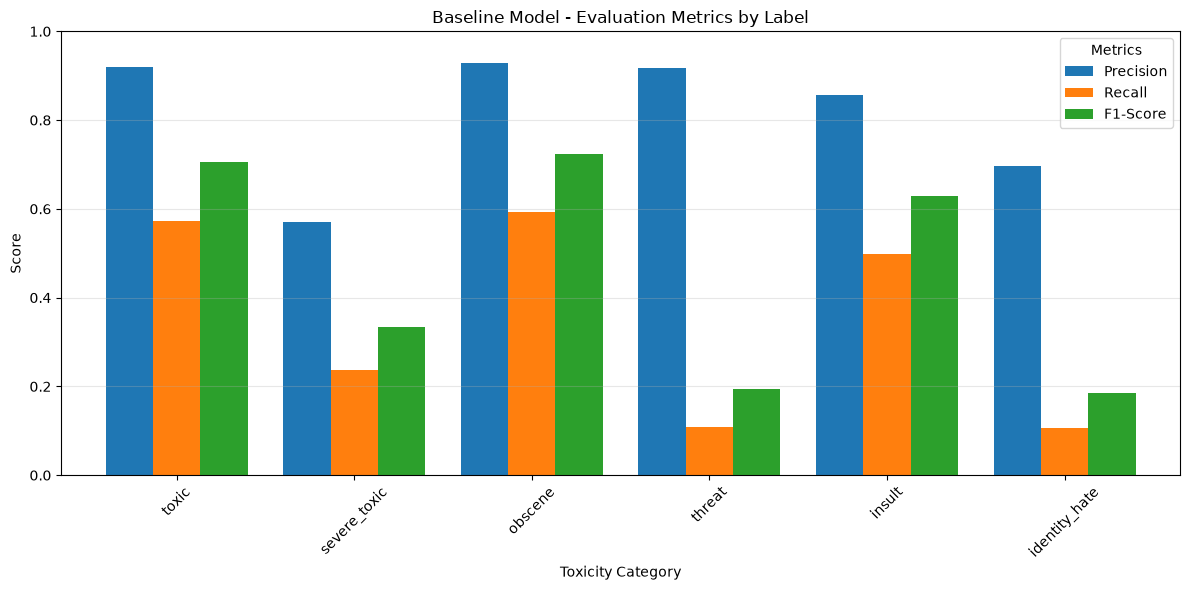

In [24]:
# Plot Evaluation Metrics
import matplotlib.pyplot as plt
evaluation_results.set_index("Label").plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Baseline Model - Evaluation Metrics by Label")
plt.xlabel("Toxicity Category")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.legend(title="Metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Saving Baseline Results

In this section, we save the baseline model evaluation results.

These results will be used as a reference when comparing the performance of different pretrained models.

In [25]:
import os

# Create Metrics Directory
os.makedirs("../results/metrics", exist_ok=True)

# Save Evaluation Metrics
evaluation_results.to_csv(
    "../results/metrics/baseline_metrics.csv",
    index=False
)

# Save Classification Report
with open("../results/metrics/baseline_classification_report.txt", "w") as file:
    file.write(report)

print("Baseline evaluation results saved successfully!")

Baseline evaluation results saved successfully!


## 10. Saving Model Performance Information

In this section, we save the baseline model's training and prediction times.

These measurements will be used to compare computational efficiency across different models.

In [26]:
# Save Baseline Model Performance Information

baseline_performance = pd.DataFrame({
    "Model": ["TF-IDF + Logistic Regression"],
    "Training Time (seconds)": [training_time],
    "Prediction Time (seconds)": [prediction_time]
})

baseline_performance.to_csv(
    "../results/metrics/baseline_performance.csv",
    index=False
)

display(baseline_performance.round(3))

print("Baseline performance information saved successfully!")

,Model,Training Time (seconds),Prediction Time (seconds)
0,TF-IDF + Logistic Regression,6.136,0.027


Baseline performance information saved successfully!


## 11. Baseline Model Error Analysis

In this section, we analyze the baseline model's predictions to identify classification errors.

We examine:
- False Positive predictions.
- False Negative predictions.
- Misclassified comments for each toxicity category.

This analysis helps us understand the limitations of the baseline model and identify areas for improvement.

In [27]:
X_val_text = pd.read_csv(
    "../data/processed/train_processed.csv"
)["cleaned_text"].iloc[y_val.index]

In [28]:
# Create a DataFrame for Error Analysis

error_analysis = pd.DataFrame({
    "comment": X_val_text.reset_index(drop=True),
    "actual_toxic": y_val["toxic"].values,
    "predicted_toxic": y_val_pred[:, 0]
})

# Identify False Positives and False Negatives

false_positives = error_analysis[
    (error_analysis["actual_toxic"] == 0) &
    (error_analysis["predicted_toxic"] == 1)
]

false_negatives = error_analysis[
    (error_analysis["actual_toxic"] == 1) &
    (error_analysis["predicted_toxic"] == 0)
]

print("False Positives:", len(false_positives))
print("False Negatives:", len(false_negatives))

print("\nFalse Negative Examples:")
display(false_negatives[["comment"]].head(5))

False Positives: 153
False Negatives: 1290

False Negative Examples:


,comment
48,""" as for your claims of """"stalking"""", that is absolute rubbish and serves only to aggravate the situation. i have assumed good faith (and good intentions) on your part, and have never suggested (or seen reason to suggest) that you might have some ulterior motive in mass-adding links to one specific company's web page. nor, for that matter, have i ever made any suggestion that this is an """"administrative"""" matter or even mentioned such a role. (clearly, as a party to this disagreement, i would not do so at any rate as it would be a conflict of interest.) i would ask that you thus extend the same good faith toward me, rather than making spurious and unfounded accusations. ''''''chatspy """
51,get fucked up. get fuckeeed up. got a drink that you cant put down???/ get fuck up get fucked up. i'm fucked up right now!
84,""" christ. """"iq is selected for therefore every population has the same iq."""" never ceases to amaze me. """
90,"personal attacks in fruit brute vfd my apologies if i'm being to critical, but i feel that many of the comments made in the fruit brute vfd debate were far from reasonable. there had to be a more diplomatic way to disagree with 's assertion on the initial sentence than don't lie, it makes you look even more juvenile.... learn to face up to when you've goofed, it will go a long way in your life the attacks do to his age certainly border on a personal attack. were bart133 forty, sixty, or eighty, would you have included the comment on how 'juvenile' he is? i don't expect you to apologise to anyone, but i want to make it clear that i consider your comments in this vfd debate inappropriate, and i think their are many members of the community who would agree with me. talk 06:46, 2005 feb 7 (utc)"
96,""" hi thanks for our kind words. see you around ) talk """


In [29]:
# Display Full False Negative Examples

pd.set_option("display.max_colwidth", None)

print("False Negative Examples:")
display(
    false_negatives[["comment"]].head(10)
)

print("\nFalse Positive Examples:")
display(
    false_positives[["comment"]].head(10)
)

False Negative Examples:


,comment
48,""" as for your claims of """"stalking"""", that is absolute rubbish and serves only to aggravate the situation. i have assumed good faith (and good intentions) on your part, and have never suggested (or seen reason to suggest) that you might have some ulterior motive in mass-adding links to one specific company's web page. nor, for that matter, have i ever made any suggestion that this is an """"administrative"""" matter or even mentioned such a role. (clearly, as a party to this disagreement, i would not do so at any rate as it would be a conflict of interest.) i would ask that you thus extend the same good faith toward me, rather than making spurious and unfounded accusations. ''''''chatspy """
51,get fucked up. get fuckeeed up. got a drink that you cant put down???/ get fuck up get fucked up. i'm fucked up right now!
84,""" christ. """"iq is selected for therefore every population has the same iq."""" never ceases to amaze me. """
90,"personal attacks in fruit brute vfd my apologies if i'm being to critical, but i feel that many of the comments made in the fruit brute vfd debate were far from reasonable. there had to be a more diplomatic way to disagree with 's assertion on the initial sentence than don't lie, it makes you look even more juvenile.... learn to face up to when you've goofed, it will go a long way in your life the attacks do to his age certainly border on a personal attack. were bart133 forty, sixty, or eighty, would you have included the comment on how 'juvenile' he is? i don't expect you to apologise to anyone, but i want to make it clear that i consider your comments in this vfd debate inappropriate, and i think their are many members of the community who would agree with me. talk 06:46, 2005 feb 7 (utc)"
96,""" hi thanks for our kind words. see you around ) talk """
98,"thanks much - however, if it's been resolved, why is it that today, when i didn't write anything in edit summary, camera put its ad in my edit summary box?1equalvoice1 (talk)"
131,"tcm i can find no evidence that acupressure is a tcm, rather than derived from tcm. if no one objects i'll place a citation note in the article."
180,""" 29 august 2006 wow. i understand that the sentance i """"added"""" was not crucial and really does not change the content. but what is this?! has the community not gotten smaller? was it not caused by the automobile? have i not sourced the statement as asked? is it not a fact? is it not information? does it not help inform people as to why foresters falls is not as large as it seemingly once was? is it not the only peice of information in the article that bridges the span of time between 1870 and present? is the usfullness of the edit the only criteria used to determine if it will be reverted or not? if so it should be noted that i simply re-added the information after it was removed. was not the removal frivilous and unwarranted? what is the problem? why insist on the absence of this statement? it is unjustifiable. it is negligible. i am re adding the information as it is: a)factual, b) sourced, and c) informative. i assume that since there is no reason to remove it again (or in the first place) that you and all other wiki nazis will relax. if you are concerned with useless edits please see the edit fom the 26th. i know it was carried out by the great infallable mindmatrix but imho that was the first useless change. """
230,"i don't know the answer to this, but legally, how is it possible for a private citizen to violate another private citizen's civil rights? i don't know if this is the section nelson was charged under in the federal case, but if anyone could explain this, i would appreciate it. you can argue whether or not the outcome of the state murder trial was justified, that's really not my concern here, since it's a dead letter. i'm concerned about whether the subsequent civil rights prosecution was legal. if the state murder acquittal was a miscarriage of justice, it's not the first time. 


False Positive Examples:


,comment
158,"once again, i responded to milemoney's reasoning for his edit and i gave my reasoning for my edit. yes, it is absolutely relevant to this page. there are other places for the discussion on income inequality than in the progressive tax article."
203,"i did research thank you very much, and it is not in the relevance of the article. i think you may have to reseacrh wp:el to amke sure you realise the facts about why these links are being deleted. i am willing to agree with people that only the official sites should be there, therefore i shall delete the game site and the otehrs now."
251,""" yes they are indeed. i've replaced that second one with a summary of women's rights talk """
353,"that's a rather feeble premise to argue showing an excessive number of photos prominently showing 24 different women's vaginas, compared to one human male penis 3/4 of the way down the page on the equivalent article for male genitalia. this demonstrates the overwhelming male bias in editorial content on wikipedia. 86.13.182.103"
637,"""40, 25 january 2008 (utc) no, i am not being uncivil. try uuser:lbrun12415. he's called other users a waste of sperm, a moron, etc. block him, the one who's truly uncivil. - rikara, i recommend you cool it. yelling and arguing is not going to get you anything. take a breather and come back when you're feeling calmer. otherwise you will find your talk page protected and you will be forced to take a breather. - i have seen nothing of the sort from that user (who has since been renamed), at the very least not in this current situation. -'''' (blah v^_^v) 23:"""
784,""" when i looked at the cato edit, it was simply a removal of the reference, the addition of another donor, and a change in the language. without an edit summary to explain, the changes were unjustified. (your clarification certainly helps.) thanks, also, for adding the reference on summers. frankly, i did not look at the sources removed or added. my main concern was the unexplained edits. summaries are important! and then i saw that the messages about these same concerns from a while back, so my message is more of a reminder. most importantly, you are incorrect if you think it is """"not against the rules to add unsourced material"""". one of the core content policies is wp:v, and wp:rs allows us to carry out that policy. happy editing. – """
888,. ok dennis brown thanks for telling me i was taking this a bit way too serious ill be careful for this time stupid bots.
1136,"fan related links hello all. i know some of you may have found my additions irritating on this site: more specifically my linking a youtube clip of my friend on the news giving his fresh impressions of the movie, just after viewing it. let me just say that my friend is a very dedicated fan, which the news clip even attests to, and although his comments might seem a bit unusual, i think they're interesting in that they speak unique ways a fan could view a movie. as far as copyright infringement or irrelevance, i've already addressed how the clip is relevant, so i'll say what i have to on ip. having worked in an intellectual property firm for a few years, and now as a student in law school, i am convinced from what i know of the law that this clip does not infringe upon any rights of the film, and any infringement that has occurred thus far from it has been attended to by the abc news team for the release of their story. so, please, can we try to negotiate or come to some sort of agreement that it will be okay to leave this clip up? i'm new to wiki-editing, but believe this clip would make a nice addition to the spider-man 3 site. i'm sure lots of fans would find it funny and interesting, to say the least. so what do you say, people?"
1247,""" homosexuality hi everyone, i would like to come out and admit my homosexuality. cheers! ☿/talk """
1415,"intro this is the intro which was on the palpatine page for a very long time: once an ambitious senator in the galactic senate, the

## 12. Error Analysis Conclusions

The error analysis revealed several limitations of the baseline model.

### Key Findings

1. The model produced 153 False Positive predictions.
2. The model produced 1,290 False Negative predictions.
3. Some toxic comments were missed because of contextual language and complex sentence structures.
4. Some non-toxic comments were incorrectly classified due to sensitive words or strong expressions used in discussions.
5. TF-IDF and Logistic Regression have limited ability to understand context and semantic relationships.

### Conclusion

The baseline model provides a useful starting point for toxic comment classification. However, its performance indicates that more advanced NLP models may be needed to improve toxicity detection, especially Recall.

These findings will help us interpret and compare the performance of pretrained Transformer models.

In [30]:
# Combine False Positives and False Negatives

false_positives = false_positives.copy()
false_negatives = false_negatives.copy()

false_positives["error_type"] = "False Positive"
false_negatives["error_type"] = "False Negative"

error_results = pd.concat(
    [false_positives, false_negatives],
    ignore_index=True
)

# Save Error Analysis Results

error_results.to_csv(
    "../results/metrics/baseline_error_analysis.csv",
    index=False
)

print("Error analysis results saved successfully!")

Error analysis results saved successfully!
